# Pipeline results so far (Steps 2–4) + a first look at the standard filter (Step 5)

Research plan: `../../Research_Plan.md`. This notebook just reads what the scripts in `../scripts/` wrote, so it's a view on results, not where the work happens. Re-run after re-running the scripts.

Data used in this run: MIT-BIH Arrhythmia, NSTDB (noise), QTDB. PTB-XL not downloaded yet, so the rhythm task is missing from everything below.

Step 1 (novelty check / reading) is still ongoing in parallel, not covered here.

In [1]:
import sys, gzip
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESEARCH = Path.cwd().parent if Path.cwd().name == "notebooks" else Path("research")
sys.path.insert(0, str(RESEARCH / "scripts"))
from common import make_noisy, power, snr_db, DEFAULT_SNRS, NOISE_TYPES

pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 100
RESEARCH

PosixPath('/home/user/ecg_denoise/research')

## Step 2 – data inventory

What's actually on disk and which labels exist. Output of `step2_inventory.py`.

In [2]:
inv = pd.read_csv(RESEARCH / "results" / "data_inventory.csv")
keep = ["wfdb_records", "sampling_rates_hz", "n_channels", "total_hours",
        "duration_sec_min/median/max", "total_labelled_beats"]
inv[inv["item"].isin(keep)].pivot(index="item", columns="dataset", values="value").reindex(keep)

dataset,mitdb,nstdb,qtdb
item,,,
wfdb_records,48,15,105
sampling_rates_hz,{360: 48},{360: 15},{250: 105}
n_channels,{2: 48},{2: 15},{2: 105}
total_hours,24.07,7.52,26.25
duration_sec_min/median/max,1805.6 / 1805.6 / 1805.6,1805.6 / 1805.6 / 1805.6,900.0 / 900.0 / 900.0
total_labelled_beats,109494,NaN,NaN


In [3]:
# which annotation files do we have -> which tasks are possible
inv[inv["item"].str.startswith("records_with_")][["dataset", "item", "value"]]

,dataset,item,value
9,mitdb,records_with_.atr (reference beat labels),48
21,nstdb,records_with_.atr (reference beat labels),12
34,qtdb,records_with_.atr (reference beat labels),82
35,qtdb,records_with_.q1c (manual wave boundaries (car...,105
36,qtdb,records_with_.q2c (manual wave boundaries (car...,11
37,qtdb,records_with_.pu (automatic wave boundaries),105
38,qtdb,records_with_.pu0 (automatic wave boundaries ch0),105
39,qtdb,records_with_.pu1 (automatic wave boundaries ch1),105
40,qtdb,records_with_.man (manual beat annotations),105


So: MIT-BIH has beat labels (`.atr`) for all 48 records → heartbeat detection task is fine.
QTDB has the cardiologist wave boundaries (`.q1c`) on all 105 records → wave timing task is fine.
NSTDB has the three noise recordings bw / ma / em (the 118eXX / 119eXX records are MIT-BIH + noise premixed, we don't use those, we mix our own).

Rhythm classification needs PTB-XL. TODO.

## Step 3 – splits

Patient-wise splits, and the NSTDB noise cut in time so test noise is never seen in training. `step3_splits.py` also runs the leakage check.

In [4]:
print((RESEARCH / "splits" / "split_check.txt").read_text())

seed=0
PASS: 133 patient groups, each in exactly one split (checked across MIT-BIH and QTDB together).
PASS: noise 'bw' train/val/test ranges do not overlap
PASS: noise 'em' train/val/test ranges do not overlap
PASS: noise 'ma' train/val/test ranges do not overlap
mitdb: {'test': '21 records / 21 patients', 'train': '19 records / 18 patients', 'val': '4 records / 4 patients'}
qtdb: {'test': '27 records / 27 patients', 'train': '57 records / 57 patients', 'val': '19 records / 19 patients'}



In [5]:
mit = pd.read_csv(RESEARCH / "splits" / "mitdb.csv", dtype={"record": str})
qt = pd.read_csv(RESEARCH / "splits" / "qtdb.csv", dtype={"record": str})
pd.concat({
    "mitdb records": mit["split"].value_counts(),
    "qtdb records": qt["split"].value_counts(),
    "qtdb with q1c": qt[qt["has_q1c"]]["split"].value_counts(),
}, axis=1).fillna(0).astype(int)

,mitdb records,qtdb records,qtdb with q1c
split,,,
test,21,27,27
train,19,57,57
excluded_paced,4,2,2
val,4,19,19


In [6]:
# MIT-BIH: which records went where (DS1/DS2 of de Chazal, 202 moved to train because same patient as 201)
for s, g in mit.groupby("split"):
    print(f"{s:15s}", " ".join(g["record"]))

excluded_paced  102 104 107 217
test            100 103 105 111 113 117 121 123 200 210 212 213 214 219 221 222 228 231 232 233 234
train           101 106 108 109 112 115 116 118 119 124 201 202 205 207 209 215 220 223 230
val             114 122 203 208


In [7]:
noise = pd.read_csv(RESEARCH / "splits" / "nstdb_noise.csv")
noise

,noise_record,split,start_sample,end_sample,fs,minutes
0,bw,train,0,390000,360,18.06
1,bw,val,390000,520000,360,6.02
2,bw,test,520000,650000,360,6.02
3,ma,train,0,390000,360,18.06
4,ma,val,390000,520000,360,6.02
5,ma,test,520000,650000,360,6.02
6,em,train,0,390000,360,18.06
7,em,val,390000,520000,360,6.02
8,em,test,520000,650000,360,6.02


Only ~6 min of test noise per type (20% of 30 min). Enough for the test windows since each window draws a random 10 s segment, but segments will repeat across windows. Worth remembering when we interpret per-window variance later.

## Step 4 – noisy test signals

10 s windows, channel 0, noise added at 24 / 12 / 6 / 0 / −6 dB for bw, ma, em and a mix. Same noise segment used at every level for a given window so the levels are paired. Only the *recipe* is saved (which segment, start, scale); `make_noisy()` rebuilds the signal exactly.

In [8]:
pd.concat([pd.read_csv(RESEARCH / "results" / f"E0_noise_build_{s}.csv") for s in ["test", "val"]])

,dataset,split,fs,windows,records,noisy_signals,max_snr_error_db
0,mitdb,test,360,3780,21,75600,7.105427e-15
1,qtdb,test,250,2422,27,48440,7.105427e-15
0,mitdb,val,360,720,4,14400,7.105427e-15
1,qtdb,val,250,1698,19,33960,7.105427e-15


In [9]:
rec = pd.read_csv(RESEARCH / "recipes" / "mitdb_test.csv.gz")
print(rec.shape)
rec.head(8)

(79380, 13)


,dataset,split,window_id,record,start_sample,fs,noise_type,snr_db,start_bw,start_ma,start_em,scale,achieved_snr_db
0,mitdb,test,0,100,0,360,none,clean,-1,-1,-1,0.000000,inf
1,mitdb,test,0,100,0,360,bw,24,107518,-1,-1,0.027107,24.0
2,mitdb,test,0,100,0,360,bw,12,107518,-1,-1,0.107915,12.0
3,mitdb,test,0,100,0,360,bw,6,107518,-1,-1,0.215319,6.0
4,mitdb,test,0,100,0,360,bw,0,107518,-1,-1,0.429618,0.0
5,mitdb,test,0,100,0,360,bw,-6,107518,-1,-1,0.857201,-6.0
6,mitdb,test,0,100,0,360,ma,24,-1,80511,-1,0.050254,24.0
7,mitdb,test,0,100,0,360,ma,12,-1,80511,-1,0.200063,12.0


In [10]:
# sanity: achieved SNR == target SNR (should be numerically exact)
noisy_rows = rec[rec.noise_type != "none"]
err = (noisy_rows["achieved_snr_db"] - noisy_rows["snr_db"].astype(float)).abs()
print("max |achieved - target| =", err.max(), "dB")
noisy_rows.groupby(["noise_type", "snr_db"]).size().unstack()

max |achieved - target| = 4.440892098500626e-15 dB


snr_db,-6,0,12,24,6
noise_type,,,,,
bw,3780,3780,3780,3780,3780
em,3780,3780,3780,3780,3780
ma,3780,3780,3780,3780,3780
mix,3780,3780,3780,3780,3780


Rebuild one window from the recipe and look at it at every level. (Needs `data_out/`, which is local only.)

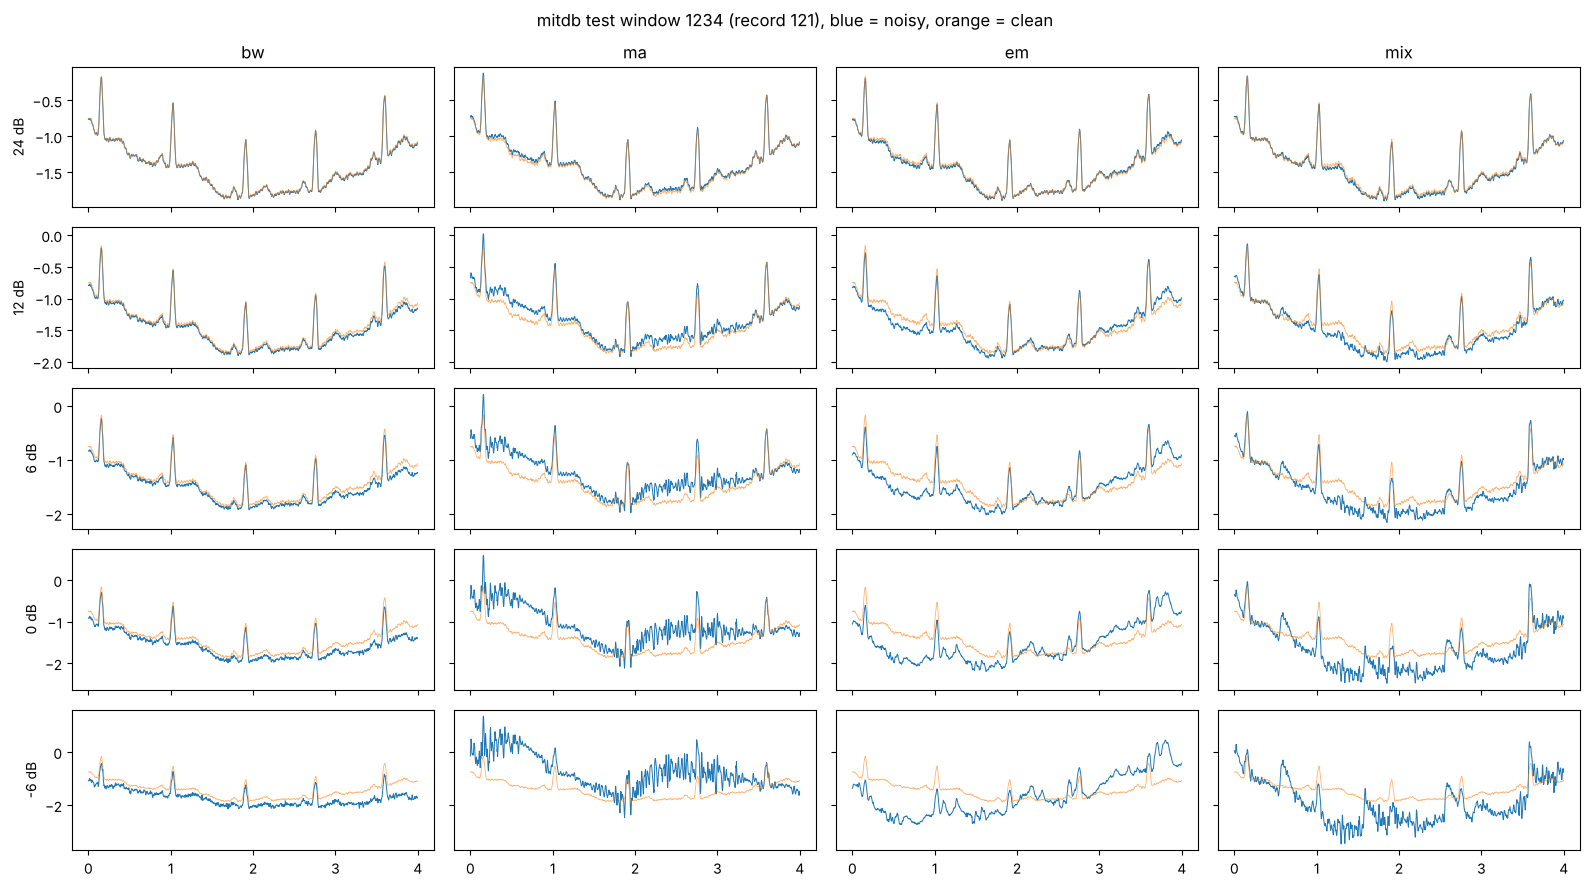

In [11]:
clean = np.load(RESEARCH / "data_out" / "mitdb_test_clean.npz")
X, fs = clean["X"].astype(float), int(clean["fs"])
bank = dict(np.load(RESEARCH / "data_out" / f"noise_bank_test_{fs}.npz"))

wid = 1234
x = X[wid]
rows = rec[rec.window_id == wid]
levels = [s for s in DEFAULT_SNRS if s != "clean"]
t = np.arange(len(x)) / fs
show = slice(0, 4 * fs)

fig, axes = plt.subplots(len(levels), 4, figsize=(16, 9), sharex=True, sharey="row")
for j, ntype in enumerate(NOISE_TYPES + ["mix"]):
    for i, s in enumerate(levels):
        r = rows[(rows.noise_type == ntype) & (rows.snr_db.astype(str) == str(s))].iloc[0]
        y = make_noisy(x, bank, r.to_dict())
        ax = axes[i, j]
        ax.plot(t[show], y[show], lw=0.7)
        ax.plot(t[show], x[show], lw=0.6, alpha=0.6)
        if i == 0: ax.set_title(ntype)
        if j == 0: ax.set_ylabel(f"{s} dB")
fig.suptitle(f"mitdb test window {wid} (record {rows.record.iloc[0]}), blue = noisy, orange = clean")
fig.tight_layout();

Looks right. bw is slow drift, ma is the high-freq fuzz, em has the big excursions. At −6 dB the QRS is still visible for bw but basically gone for em, which matches what you'd expect.

All the Step 4 figures (5 random windows × all levels, per dataset and noise type) are in `../figures/noise_examples/`.

## Step 5 (preview only) – does the simplest cleaner help?

Not the full Step 5. Just cleaner #2 from the plan (Butterworth 0.5–40 Hz band-pass + 60 Hz notch, zero-phase) applied to 300 random test windows per dataset, to check the Step 4 data is usable and get a first feel for P1/P3. `step5_preview_filter.py`.

SNR here = 10 log10(P_clean / P_error), mean removed, where error = output − clean reference.

In [12]:
e1 = {ds: pd.read_csv(RESEARCH / "results" / f"E1_preview_filter_{ds}.csv") for ds in ["mitdb", "qtdb"]}
e1["mitdb"].head()

,window_id,record,noise_type,snr_db,snr_in_db,snr_out_db,rmse_noisy,rmse_cleaned,rel_distortion,snr_gain_db
0,2838,222,none,clean,inf,4.516841,0.000000,0.242068,0.594508,-inf
1,2838,222,bw,24,2.400000e+01,4.517830,0.007675,0.242089,0.594441,-19.482170
2,2838,222,bw,12,1.200000e+01,4.492864,0.030553,0.242221,0.596152,-7.507136
3,2838,222,bw,6,6.000000e+00,4.396358,0.060962,0.242558,0.602812,-1.603642
4,2838,222,bw,0,-2.951426e-08,4.008626,0.121635,0.243775,0.630331,4.008626


In [13]:
def gain_table(df):
    d = df[df.noise_type != "none"].copy()
    d["snr_db"] = d["snr_db"].astype(int)
    d["gain"] = d["snr_out_db"] - d["snr_in_db"]
    return d.pivot_table(index="snr_db", columns="noise_type", values="gain", aggfunc="median") \
            .reindex(levels)[NOISE_TYPES + ["mix"]].round(1)

for ds, df in e1.items():
    print(f"--- {ds}: median SNR gain (dB) after filter ---")
    print(gain_table(df), "\n")

--- mitdb: median SNR gain (dB) after filter ---
noise_type    bw    ma    em   mix
snr_db                            
 24        -12.5 -12.6 -12.7 -12.6
 12         -0.6  -1.3  -2.5  -1.7
 6           5.3   2.7   0.1   2.0
 0          10.4   5.2   1.2   3.7
-6          14.3   6.4   1.9   4.7 

--- qtdb: median SNR gain (dB) after filter ---
noise_type    bw    ma    em   mix
snr_db                            
 24        -10.7 -10.7 -10.9 -10.7
 12          1.2   0.2  -1.3  -0.2
 6           6.9   3.8   0.6   2.9
 0          11.6   5.7   1.4   4.4
-6          15.3   6.6   1.7   5.0 



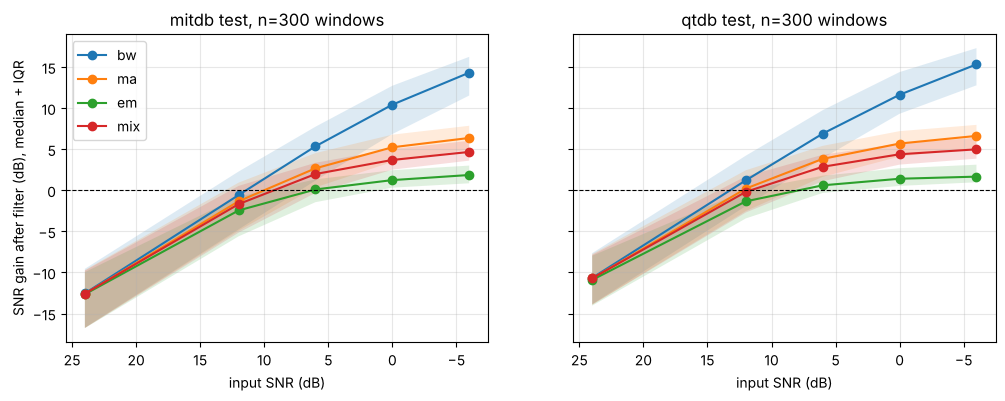

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (ds, df) in zip(axes, e1.items()):
    d = df[df.noise_type != "none"].copy()
    d["snr_db"] = d["snr_db"].astype(int)
    d["gain"] = d["snr_out_db"] - d["snr_in_db"]
    for ntype in NOISE_TYPES + ["mix"]:
        g = d[d.noise_type == ntype].groupby("snr_db")["gain"]
        med, lo, hi = g.median(), g.quantile(0.25), g.quantile(0.75)
        ax.plot(med.index, med.values, marker="o", label=ntype)
        ax.fill_between(med.index, lo.values, hi.values, alpha=0.15)
    ax.axhline(0, color="k", lw=0.8, ls="--")
    ax.invert_xaxis()
    ax.set_xlabel("input SNR (dB)"); ax.set_title(f"{ds} test, n=300 windows")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("SNR gain after filter (dB), median + IQR")
axes[0].legend();

Same picture on both datasets: the filter helps when the input is bad (≤ 6 dB) and hurts when the input is already decent (≥ 12 dB). Crossover somewhere between 6 and 12 dB for every noise type. bw is the easy one (it's almost all below 0.5 Hz), em the hard one (overlaps the QRS band).

The −12 dB at 24 dB input is striking: the output is *worse* than the input by a lot. That's because the output SNR saturates around 11–13 dB no matter what you put in. Which brings up the clean-input question.

mitdb: clean input -> output SNR vs reference: median 11.5 dB, min 0.7; relative RMS change median 0.27, 98% of windows changed > 10%
qtdb: clean input -> output SNR vs reference: median 13.4 dB, min -0.4; relative RMS change median 0.21, 94% of windows changed > 10%


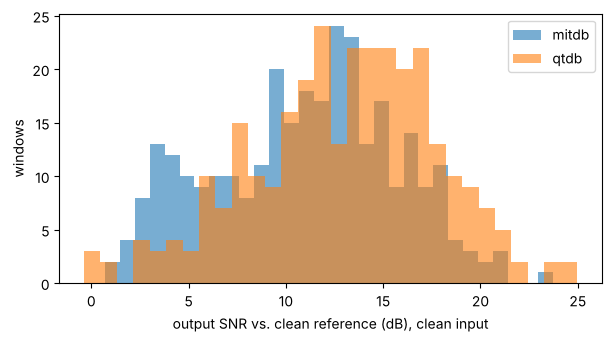

In [15]:
# what does the filter do to an already-clean window?
for ds, df in e1.items():
    c = df[df.noise_type == "none"]
    print(f"{ds}: clean input -> output SNR vs reference: median {c.snr_out_db.median():.1f} dB, "
          f"min {c.snr_out_db.min():.1f}; "
          f"relative RMS change median {c.rel_distortion.median():.2f}, "
          f"{(c.rel_distortion > 0.1).mean()*100:.0f}% of windows changed > 10%")

fig, ax = plt.subplots(figsize=(7, 3.5))
for ds, df in e1.items():
    ax.hist(df[df.noise_type == "none"]["snr_out_db"], bins=30, alpha=0.6, label=ds)
ax.set_xlabel("output SNR vs. clean reference (dB), clean input"); ax.set_ylabel("windows"); ax.legend();

### Hmm – is that really "distortion"?

The filter changes ~all clean windows by >10% RMS. Before reading that as support for P3 (cleaning hurts clean signals), look at *what* it removes:

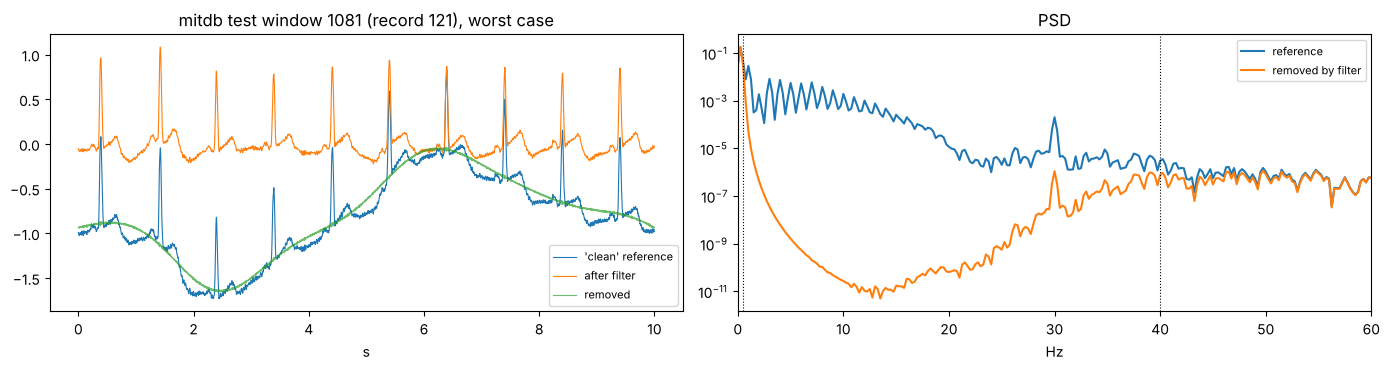

In [16]:
from scipy.signal import butter, sosfiltfilt, iirnotch, filtfilt, welch

def standard_filter(x, fs):
    sos = butter(4, [0.5, 40], btype="bandpass", fs=fs, output="sos")
    b, a = iirnotch(60, Q=30, fs=fs)
    return filtfilt(b, a, sosfiltfilt(sos, x))

# pick the clean window the filter changed the most
c = e1["mitdb"][e1["mitdb"].noise_type == "none"]
wid = int(c.sort_values("snr_out_db").iloc[0].window_id)
x = X[wid]; y = standard_filter(x, fs)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].plot(t, x, lw=0.8, label="'clean' reference")
axes[0].plot(t, y, lw=0.8, label="after filter")
axes[0].plot(t, x - y, lw=0.8, alpha=0.7, label="removed")
axes[0].set_title(f"mitdb test window {wid} (record {c[c.window_id==wid].record.iloc[0]}), worst case")
axes[0].set_xlabel("s"); axes[0].legend(fontsize=8)

f, Pxx = welch(x - x.mean(), fs, nperseg=fs * 4)
f2, Prem = welch(x - y, fs, nperseg=fs * 4)
axes[1].semilogy(f, Pxx, label="reference"); axes[1].semilogy(f2, Prem, label="removed by filter")
axes[1].axvline(0.5, color="k", ls=":", lw=0.8); axes[1].axvline(40, color="k", ls=":", lw=0.8)
axes[1].set_xlim(0, 60); axes[1].set_xlabel("Hz"); axes[1].set_title("PSD"); axes[1].legend(fontsize=8)
fig.tight_layout();

Right, so most of what gets removed is the record's own baseline wander below 0.5 Hz (and a bit above 40 Hz). The MIT-BIH "clean" recordings aren't actually clean in that band. So the "distortion on clean input" number for this filter is partly the filter doing its job on wander that's in the reference, and partly real smoothing of the QRS. Can't separate the two with the current metric.

Consequences for Step 5 proper:
- need an in-band metric (e.g. compare after high-passing both reference and output), or a cleaner reference, before P3 can be tested with this filter
- this won't be an issue in the same way for the neural cleaners, but it *will* matter when we compare them against the filter baseline
- it's also exactly why the task-level outcomes (beat detection F1, QT error) matter more than SNR. SNR vs an imperfect reference is misleading here.

## Where this leaves us

| Step | Status |
|---|---|
| 1 novelty check | in progress (reading) |
| 2 data inventory | done for MIT-BIH, NSTDB, QTDB; PTB-XL / SimEMG / wearable missing |
| 3 splits | done, leakage check PASS |
| 4 noisy sets | done (test + val) for mitdb, qtdb |
| 5 cleaners | preview only, filter baseline. DWT + FCN-DAE not started |

Next: finish the reading table (D1), get PTB-XL in and rerun 2–4, then Step 5 properly with an in-band metric added to E1.